In [3]:
import osmnx as ox
import geopandas as gpd

print('ox', ox.__version__)
print('geo', gpd.__version__)

ox 2.1.1
geo 1.2.0


In [4]:
place = "Almaty, Kazakhstan"
tags = {"amenity" : "cafe"}

cafes = ox.features_from_place(place,tags)

In [7]:
print(cafes.shape) # size of dataset
print(cafes.columns.tolist())

(731, 116)
['geometry', 'amenity', 'name', 'internet_access', 'addr:housenumber', 'addr:street', 'check_date', 'name:kk', 'name:tr', 'opening_hours', 'indoor_seating', 'outdoor_seating', 'email', 'name:en', 'phone', 'website', 'cuisine', 'addr:city', 'addr:country', 'smoking', 'contact:phone', 'contact:website', 'addr:street:kk', 'addr:street:ru', 'contact:instagram', 'start_date', 'air_conditioning', 'bar', 'delivery', 'drive_through', 'highchair', 'name:ru', 'fixme', 'source', 'note', 'bic', 'brand', 'brand:wikidata', 'official_name', 'takeaway', 'addr:postcode', 'description', 'level', 'wheelchair', 'diet:vegan', 'diet:vegetarian', 'operator', 'contact:email', 'facebook', 'internet_access:fee', 'site_name', 'addr:unit', 'self_service', 'toilets', 'website:menu', 'check_date:opening_hours', 'opening_hours:signed', 'payment:cash', 'payment:credit_cards', 'payment:debit_cards', 'brand:wikipedia', 'payment:mastercard', 'payment:visa', 'contact:facebook', 'addr:floor', 'check_date:toilet

In [8]:
cafes.head()

geometry amenity             name  \
element id                                                              
node    636757283  POINT (76.94064 43.25706)    cafe  Самба-гриль-Бар   
        636764015  POINT (76.89885 43.29805)    cafe             Баян   
        636782439  POINT (76.91463 43.26782)    cafe              NaN   
        636782444  POINT (76.92903 43.26952)    cafe            Амара   
        636815207  POINT (76.90153 43.24348)    cafe           Тайфун   

                  internet_access addr:housenumber addr:street check_date  \
element id                                                                  
node    636757283             NaN              NaN         NaN        NaN   
        636764015             NaN              NaN         NaN        NaN   
        636782439             NaN              NaN         NaN        NaN   
        636782444             NaN              NaN         NaN        NaN   
        636815207             NaN              NaN         NaN        NaN   

                  name:kk name:tr opening_hours  ... building:material  \
element id                                       ...                     
node    636757283     NaN     NaN           NaN  ...               NaN   
        636764015     NaN     NaN           NaN  ...               NaN   
        636782439     NaN     NaN           NaN  ...               NaN   
        636782444     NaN     NaN           NaN  ...               NaN   
        636815207     NaN     NaN           NaN  ...               NaN   

                  roof:shape barrier int_name addr:district description:ru  \
element id                                                                   
node    636757283        NaN     NaN      NaN           NaN            NaN   
        636764015        NaN     NaN      NaN           NaN            NaN   
        636782439        NaN     NaN      NaN           NaN            NaN   
        636782444        NaN     NaN      NaN           NaN            NaN   
        636815207        NaN     NaN      NaN           NaN            NaN   

                  seasonal addr:street:en area type  
element id                                           
node    636757283      NaN            NaN  NaN  NaN  
        636764015      NaN            NaN  NaN  NaN  
        636782439      NaN            NaN  NaN  NaN  
        636782444      NaN            NaN  NaN  NaN  
        636815207      NaN            NaN  NaN  NaN  

[5 rows x 116 columns]

In [10]:
cafes.isnull().sum()

geometry              0
amenity               0
name                164
internet_access     623
addr:housenumber    514
                   ... 
description:ru      730
seasonal            730
addr:street:en      730
area                730
type                730
Length: 116, dtype: int64

In [11]:
cafes.isna().mean()

geometry            0.000000
amenity             0.000000
name                0.224350
internet_access     0.852257
addr:housenumber    0.703146
                      ...   
description:ru      0.998632
seasonal            0.998632
addr:street:en      0.998632
area                0.998632
type                0.998632
Length: 116, dtype: float64

In [17]:
cafe_top_15 = cafes.isna().mean().sort_values(ascending=True)
cafe_top_15.head(15)

geometry            0.000000
amenity             0.000000
name                0.224350
cuisine             0.621067
opening_hours       0.678523
addr:street         0.697674
addr:housenumber    0.703146
outdoor_seating     0.793434
addr:city           0.829001
building            0.835841
internet_access     0.852257
check_date          0.871409
name:en             0.875513
contact:phone       0.882353
contact:website     0.883721
dtype: float64

In [27]:
unique_geom_types = cafes.geometry.geom_type
unique_geom_types.value_counts()

Point      608
Polygon    123
Name: count, dtype: int64

In [ ]:
print(cafes['name'].value_counts(dropna=False))
print(cafes['name'].nunique())

name
NaN                  164
Degirmen              35
Starbucks             21
Nedelka                8
Mixue                  8
                    ... 
Уют                    1
Park cafe              1
Aspan Terrenqour       1
Ozen Ulken Almaty      1
Umai                   1
Name: count, Length: 426, dtype: int64
425


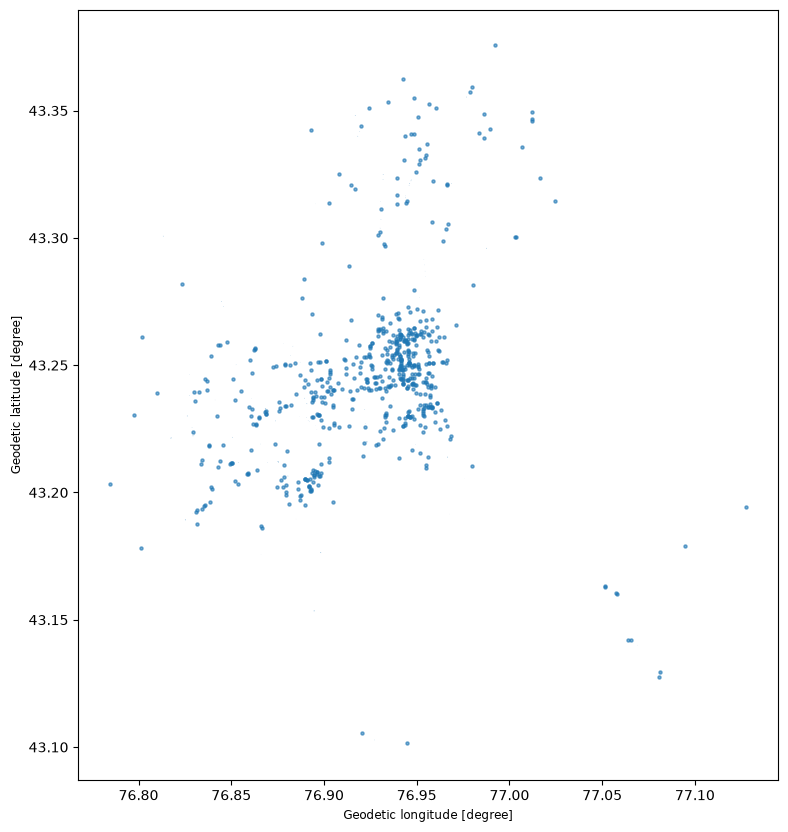

In [43]:
import matplotlib.pyplot as plt
ax = cafes.plot(figsize=(10,10), markersize=5, alpha=0.6)

In [44]:
print(cafes.crs)

epsg:4326
